<a href="https://colab.research.google.com/github/stephanie-ekeji/Phishing-Website-Detection/blob/main/IS_665_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phishing Website Detection Using Machine Learning

**IS 665 – Cybersecurity Analytics**  
**Group 10: Stephanie Ekejiuba & Edel Martinez Santiago**



## Project Overview

This project focuses on using machine learning to identify phishing websites that may appear legitimate but are designed to trick users into providing personal or sensitive information. Our goal is to classify websites as phishing or legitimate while minimizing false positives and false negatives. The intended users are security teams and cybersecurity analysts who are responsible for identifying potential phishing threats.

Our primary dataset is the **UCI Phishing Websites dataset**, which contains 11,055 observations and 30 features related to URL characteristics, webpage behavior, and domain information. We are also exploring the **PhiUSIIL Phishing URL Dataset**, which was added to UCI in 2024 and contains 235,795 observations and 54 features. Since our primary dataset is older, we want to investigate whether our approach can generalize to newer phishing data. We will first examine feature compatibility between the datasets to determine whether external testing is feasible.

Our proposed approach involves preparing and analyzing the data, comparing a majority-class baseline with Logistic Regression, Decision Tree, and Random Forest models, and evaluating their performance using accuracy, precision, recall, F1-score, and false-positive and false-negative rates.

Based on feedback from our professor, we will also investigate feature importance and conduct **feature ablation experiments** to determine whether the models rely heavily on certain features. This will involve removing selected features or groups of features, retraining the models, and comparing how their performance changes. We are particularly interested in whether the models can still identify phishing websites effectively without certain URL-related features.

Our proposed performance benchmarks are **at least 90% phishing recall, a false-positive rate of no more than 10%, and an F1-score of at least 85%**. We will evaluate whether these targets are achievable and examine how performance changes when influential features are removed.

**Research Question:** How effectively can machine learning models identify phishing websites while minimizing the occurrence of false positives and false negatives?

## 2. Data Understanding

The purpose of this stage is to explore our datasets and understand their structure, features, and overall data quality before preparing them for machine learning.

We will use the **UCI Phishing Websites dataset** as our primary dataset and examine the **PhiUSIIL Phishing URL Dataset** as a potential source for later generalization testing.

For our initial analysis, we will:

- Load both datasets into Google Colab.
- Examine the number of observations, features, and data types.
- Check for missing values and duplicate records.
- Review the distribution of phishing and legitimate websites.
- Identify potential data-quality issues that may affect model performance.

These findings will help us determine what cleaning and preparation steps are needed before training and evaluating our models.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.io import arff

In [ ]:
# Read primary phishing dataset
data, meta = arff.loadarff("/content/drive/MyDrive/IS 665 Project Dataset/Training Dataset.arff")

phishing_data = pd.DataFrame(data)

phishing_data

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,b'-1',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',b'1',b'-1',b'-1'
1,b'1',b'1',b'1',b'1',b'1',b'-1',b'0',b'1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'-1'
2,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'1',b'-1',b'1',b'-1',b'1',b'0',b'-1',b'-1'
3,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'1',b'1',...,b'1',b'1',b'-1',b'-1',b'1',b'-1',b'1',b'-1',b'1',b'-1'
4,b'1',b'0',b'-1',b'1',b'1',b'-1',b'1',b'1',b'-1',b'1',...,b'-1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'1'
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11050,b'1',b'-1',b'1',b'-1',b'1',b'1',b'1',b'1',b'-1',b'-1',...,b'-1',b'-1',b'1',b'1',b'-1',b'-1',b'1',b'1',b'1',b'1'
11051,b'-1',b'1',b'1',b'-1',b'-1',b'-1',b'1',b'-1',b'-1',b'-1',...,b'-1',b'1',b'1',b'1',b'1',b'1',b'1',b'-1',b'1',b'-1'
11052,b'1',b'-1',b'1',b'1',b'1',b'-1',b'1',b'-1',b'-1',b'1',...,b'1',b'1',b'1',b'1',b'1',b'-1',b'1',b'0',b'1',b'-1'
11053,b'-1',b'-1',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'1',b'-1',...,b'-1',b'1',b'1',b'1',b'1',b'-1',b'1',b'1',b'1',b'-1'


In [ ]:
# Read external phishing dataset
phiusiil_data = pd.read_csv("/content/drive/MyDrive/IS 665 Project Dataset/PhiUSIIL_Phishing_URL_Dataset.csv")

phiusiil_data

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.000000,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.000000,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.000000,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.000000,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.000000,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235790,660997.txt,https://www.skincareliving.com,29,www.skincareliving.com,22,0,com,100.000000,1.000000,0.522907,...,1,0,1,51,7,21,187,2,191,1
235791,77185.txt,https://www.winchester.gov.uk,28,www.winchester.gov.uk,21,0,uk,100.000000,0.785714,0.028555,...,1,0,0,50,1,7,88,0,31,1
235792,622132.txt,https://www.nononsensedesign.be,30,www.nononsensedesign.be,23,0,be,100.000000,1.000000,0.003319,...,0,0,1,27,10,30,58,2,67,1
235793,7503962.txt,https://patient-cell-40f5.updatedlogmylogin.wo...,55,patient-cell-40f5.updatedlogmylogin.workers.dev,47,0,dev,28.157537,0.465116,0.000961,...,0,0,0,0,0,3,0,0,0,0


In [ ]:
# Inspect the primary dataset

print("Dataset shape:", phishing_data.shape)

print("\nColumn names:")
print(phishing_data.columns.tolist())

print("\nData types:")
print(phishing_data.dtypes)

print("\nMissing values:", phishing_data.isnull().sum().sum())

print("\nDuplicate rows:", phishing_data.duplicated().sum())

print("\nClass distribution:")
print(phishing_data["Result"].value_counts())

Dataset shape: (11055, 31)

Column names:
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']

Data types:
having_IP_Address              object
URL_Length                     object
Shortining_Service             object
having_At_Symbol               object
double_slash_redirecting       object
Prefix_Suffix                  object
having_Sub_Domain              object
SSLfinal_State                 object
Domain_registeration_length    object
Favicon                        object
port                           object
HTTPS_

In [ ]:
# Create a copy of the original dataset
phishing_clean = phishing_data.copy()

# Convert byte values into integers
for column in phishing_clean.columns:
    phishing_clean[column] = phishing_clean[column].apply(
        lambda value: int(value.decode("utf-8"))
        if isinstance(value, bytes) else int(value)
    )

# Verify the conversion
print("Data types:")
print(phishing_clean.dtypes.value_counts())

print("\nMissing values:", phishing_clean.isnull().sum().sum())

print("\nDuplicate rows:", phishing_clean.duplicated().sum())

print("\nClass distribution:")
print(phishing_clean["Result"].value_counts())

phishing_clean.head()

Data types:
int64    31
Name: count, dtype: int64

Missing values: 0

Duplicate rows: 5206

Class distribution:
Result
 1    6157
-1    4898
Name: count, dtype: int64


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


In [ ]:
# Investigate duplicate records and conflicting labels

features = phishing_clean.drop(columns=["Result"])

# Count exact duplicate rows
exact_duplicates = phishing_clean.duplicated().sum()

# Count unique feature patterns
unique_patterns = features.drop_duplicates().shape[0]

# Identify feature patterns associated with different labels
conflicting_patterns = (
    phishing_clean.groupby(list(features.columns))["Result"]
    .nunique()
)

conflicting_count = (conflicting_patterns > 1).sum()

print("Exact duplicate rows:", exact_duplicates)
print("Unique feature patterns:", unique_patterns)
print("Feature patterns with conflicting labels:", conflicting_count)

Exact duplicate rows: 5206
Unique feature patterns: 5785
Feature patterns with conflicting labels: 64


In [ ]:
# Investigate conflicting feature patterns

feature_columns = phishing_clean.columns.drop("Result").tolist()

# Count how often each feature pattern appears
pattern_summary = (
    phishing_clean
    .groupby(feature_columns)["Result"]
    .agg(
        total_records="size",
        unique_labels="nunique"
    )
    .reset_index()
)

# Keep patterns that have conflicting labels
conflicting_records = pattern_summary[
    pattern_summary["unique_labels"] > 1
]

print("Conflicting feature patterns:", len(conflicting_records))

print(
    "Total records belonging to conflicting patterns:",
    conflicting_records["total_records"].sum()
)

print("\nDistribution of repeated feature patterns:")
print(pattern_summary["total_records"].describe())

conflicting_records[
    ["total_records", "unique_labels"]
].head(10)

Conflicting feature patterns: 64
Total records belonging to conflicting patterns: 357

Distribution of repeated feature patterns:
count    5785.000000
mean        1.910977
std         1.583824
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        25.000000
Name: total_records, dtype: float64


,total_records,unique_labels
1061,3,2
1306,7,2
1308,6,2
1325,4,2
1477,3,2
1484,6,2
1544,3,2
1546,3,2
1609,3,2
1611,3,2


In [ ]:
# Compare original data with a deduplicated version

phishing_unique = phishing_clean.drop_duplicates().copy()

print("Original rows:", len(phishing_clean))
print("Rows after exact duplicate removal:", len(phishing_unique))
print("Rows removed:", len(phishing_clean) - len(phishing_unique))

print("\nOriginal class distribution:")
print(phishing_clean["Result"].value_counts(normalize=True).round(4))

print("\nClass distribution after removing duplicates:")
print(phishing_unique["Result"].value_counts(normalize=True).round(4))

Original rows: 11055
Rows after exact duplicate removal: 5849
Rows removed: 5206

Original class distribution:
Result
 1    0.5569
-1    0.4431
Name: proportion, dtype: float64

Class distribution after removing duplicates:
Result
-1    0.5162
 1    0.4838
Name: proportion, dtype: float64


In [ ]:
# Examine feature values and verify the target encoding

# List the unique values found in each column
feature_summary = pd.DataFrame({
    "Feature": phishing_clean.columns,
    "Unique_Values": [
        sorted(phishing_clean[col].unique().tolist())
        for col in phishing_clean.columns
    ],
    "Number_of_Values": [
        phishing_clean[col].nunique()
        for col in phishing_clean.columns
    ]
})

display(feature_summary)

# Display the target values separately
print("\nTarget variable (Result):")
print(phishing_clean["Result"].value_counts().sort_index())


,Feature,Unique_Values,Number_of_Values
0,having_IP_Address,"[-1, 1]",2
1,URL_Length,"[-1, 0, 1]",3
2,Shortining_Service,"[-1, 1]",2
3,having_At_Symbol,"[-1, 1]",2
4,double_slash_redirecting,"[-1, 1]",2
5,Prefix_Suffix,"[-1, 1]",2
6,having_Sub_Domain,"[-1, 0, 1]",3
7,SSLfinal_State,"[-1, 0, 1]",3
8,Domain_registeration_length,"[-1, 1]",2
9,Favicon,"[-1, 1]",2



Target variable (Result):
Result
-1    4898
 1    6157
Name: count, dtype: int64


### Data Understanding Findings

The primary UCI Phishing Websites dataset contains 11,055 observations, 30 predictor features, and one target variable (`Result`). The target uses `-1` to represent phishing websites and `1` to represent legitimate websites. The original dataset contains 4,898 phishing observations (44.31%) and 6,157 legitimate observations (55.69%).

The initial inspection found no missing values. However, 5,206 exact duplicate records were identified. Further investigation found 5,785 unique feature patterns, including 64 patterns associated with conflicting classification labels. A total of 357 original observations belong to these conflicting patterns.

The dataset's values were initially stored as byte objects and were successfully converted into integers. All predictor features contain either two or three distinct numeric values, consistent with the dataset's categorical feature structure.

Removing exact duplicates would reduce the dataset to 5,849 observations and change the class distribution to approximately 51.62% legitimate and 48.38% phishing. Because duplicate removal affects the class balance, we will consider its implications before finalizing the data used for modeling.

## Data Preparation

In this stage, we prepare the primary UCI Phishing Websites dataset for machine learning. This includes converting the feature values into a usable numeric format, investigating duplicate records and conflicting labels, and determining how to handle potential data-quality issues.

We will also examine features for possible data leakage and prepare separate training, validation, and test sets. These steps will help us evaluate the models fairly and investigate how their performance changes when influential features are removed.

In [ ]:
# Prepare feature-pattern groups for leakage-aware splitting

# Use the exact-deduplicated dataset without changing the original
phishing_model_data = phishing_unique.copy()

# Separate predictor features from the target
X = phishing_model_data.drop(columns=["Result"])
y = phishing_model_data["Result"]

# Assign the same group ID to rows with identical feature values
feature_groups = pd.factorize(
    pd.MultiIndex.from_frame(X)
)[0]

# Verify the prepared dataset
print("Observations:", len(phishing_model_data))
print("Predictor features:", X.shape[1])
print("Unique feature-pattern groups:", len(np.unique(feature_groups)))
print("\nTarget distribution:")
print(y.value_counts(normalize=True).round(4))

Observations: 5849
Predictor features: 30
Unique feature-pattern groups: 5785

Target distribution:
Result
-1    0.5162
 1    0.4838
Name: proportion, dtype: float64


In [ ]:
# Split data into training, validation, and test sets
from sklearn.model_selection import GroupShuffleSplit

# First split: 60% training and 40% temporary data
split1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.60,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X, y, groups=feature_groups)
)

# Second split: divide temporary data into validation and test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative_idx, test_relative_idx = next(
    split2.split(
        X.iloc[temp_idx],
        y.iloc[temp_idx],
        groups=feature_groups[temp_idx]
    )
)

val_idx = temp_idx[val_relative_idx]
test_idx = temp_idx[test_relative_idx]

# Create the final datasets
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

# Check split sizes and class distributions
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name}: {len(labels)} observations")
    print(labels.value_counts(normalize=True).round(4))

# Verify no feature-pattern groups overlap across splits
train_groups = set(feature_groups[train_idx])
val_groups = set(feature_groups[val_idx])
test_groups = set(feature_groups[test_idx])

print("\nGroup overlap checks:")
print("Train / Validation:", len(train_groups & val_groups))
print("Train / Test:", len(train_groups & test_groups))
print("Validation / Test:", len(val_groups & test_groups))


Training: 3508 observations
Result
-1    0.518
 1    0.482
Name: proportion, dtype: float64

Validation: 1172 observations
Result
-1    0.5222
 1    0.4778
Name: proportion, dtype: float64

Test: 1169 observations
Result
-1    0.5047
 1    0.4953
Name: proportion, dtype: float64

Group overlap checks:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0


In [ ]:
# Identify features that may require additional availability or leakage review

features_to_review = [
    "age_of_domain",
    "DNSRecord",
    "web_traffic",
    "Page_Rank",
    "Google_Index",
    "Statistical_report",
    "Domain_registeration_length"
]

# Check which features are present in our dataset
available_review_features = [
    col for col in features_to_review if col in X_train.columns
]

# Summarize their unique values and distributions using training data only
for feature in available_review_features:
    print(f"\nFeature: {feature}")
    print("Unique values:", sorted(X_train[feature].unique()))
    print("Value distribution:")
    print(X_train[feature].value_counts(normalize=True).round(4))


Feature: age_of_domain
Unique values: [np.int64(-1), np.int64(1)]
Value distribution:
age_of_domain
 1    0.5026
-1    0.4974
Name: proportion, dtype: float64

Feature: DNSRecord
Unique values: [np.int64(-1), np.int64(1)]
Value distribution:
DNSRecord
 1    0.7383
-1    0.2617
Name: proportion, dtype: float64

Feature: web_traffic
Unique values: [np.int64(-1), np.int64(0), np.int64(1)]
Value distribution:
web_traffic
 1    0.4866
 0    0.2708
-1    0.2426
Name: proportion, dtype: float64

Feature: Page_Rank
Unique values: [np.int64(-1), np.int64(1)]
Value distribution:
Page_Rank
-1    0.7032
 1    0.2968
Name: proportion, dtype: float64

Feature: Google_Index
Unique values: [np.int64(-1), np.int64(1)]
Value distribution:
Google_Index
 1    0.8295
-1    0.1705
Name: proportion, dtype: float64

Feature: Statistical_report
Unique values: [np.int64(-1), np.int64(1)]
Value distribution:
Statistical_report
 1    0.8483
-1    0.1517
Name: proportion, dtype: float64

Feature: Domain_registera

### Feature Availability and Leakage Review

We identified seven features that may require external information or historical records, including domain age, DNS records, website traffic, page ranking, Google indexing, statistical reports, and domain registration length.

All seven features were present in the training dataset. Their values were examined to understand their distributions, but this analysis alone does not establish whether they introduce data leakage.

Before finalizing the modeling approach, we will review the feature definitions and consider whether the information would realistically be available when classifying a website. We will also investigate how model performance changes when selected features are excluded.

In [ ]:
# Check for constant and identical predictor features
# Use training data only

# Find features with only one unique value
constant_features = [
    col for col in X_train.columns
    if X_train[col].nunique() == 1
]

# Find pairs of features with identical values
identical_feature_pairs = []

columns = X_train.columns.tolist()

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        if X_train[columns[i]].equals(X_train[columns[j]]):
            identical_feature_pairs.append(
                (columns[i], columns[j])
            )

print("Constant features:", constant_features)
print("Identical feature pairs:", identical_feature_pairs)
print("Total predictor features:", X_train.shape[1])

Constant features: []
Identical feature pairs: []
Total predictor features: 30


### Conflicting Labels and Modeling Decisions

The cleaned dataset contains 5,849 observations and 5,785 unique predictor feature patterns. Our earlier analysis identified 64 feature patterns associated with conflicting target labels, meaning that identical predictor values sometimes correspond to different website classifications.

For the initial modeling experiments, we will retain these observations rather than arbitrarily change or remove their labels. Because the original data does not provide sufficient information to resolve these disagreements, retaining them allows us to document this limitation transparently.

We used group-aware splitting to ensure that identical feature patterns remain within the same training, validation, or test partition. This reduces the risk of overly optimistic evaluation caused by identical predictor patterns appearing across partitions.

We will use all 30 predictors for the initial benchmark models while separately evaluating the influence of potentially dominant or externally dependent features. Additional sensitivity experiments may exclude conflicting-label patterns or selected predictors to determine how these choices affect model performance.

In [ ]:
# Verify target labels and their distributions across datasets

print("Target variable:", y.name)
print("Unique target values:", sorted(y.unique().tolist()))

print("\nOriginal dataset:")
print(phishing_clean["Result"].value_counts().sort_index())

print("\nAfter duplicate removal:")
print(phishing_unique["Result"].value_counts().sort_index())

print("\nTraining labels:")
print(y_train.value_counts().sort_index())

print("\nValidation labels:")
print(y_val.value_counts().sort_index())

print("\nTest labels:")
print(y_test.value_counts().sort_index())

Target variable: Result
Unique target values: [-1, 1]

Original dataset:
Result
-1    4898
 1    6157
Name: count, dtype: int64

After duplicate removal:
Result
-1    3019
 1    2830
Name: count, dtype: int64

Training labels:
Result
-1    1817
 1    1691
Name: count, dtype: int64

Validation labels:
Result
-1    612
 1    560
Name: count, dtype: int64

Test labels:
Result
-1    590
 1    579
Name: count, dtype: int64


In [ ]:
# Review all predictor names for the feature audit

feature_inventory = pd.DataFrame({
    "Feature": X_train.columns,
    "Unique Training Values": [
        X_train[col].nunique()
        for col in X_train.columns
    ],
    "Missing Training Values": [
        X_train[col].isna().sum()
        for col in X_train.columns
    ]
})

display(feature_inventory)

,Feature,Unique Training Values,Missing Training Values
0,having_IP_Address,2,0
1,URL_Length,3,0
2,Shortining_Service,2,0
3,having_At_Symbol,2,0
4,double_slash_redirecting,2,0
5,Prefix_Suffix,2,0
6,having_Sub_Domain,3,0
7,SSLfinal_State,3,0
8,Domain_registeration_length,2,0
9,Favicon,2,0


In [ ]:
# Inspect the original ARFF dataset metadata

print("Dataset relation:")
print(meta.name)

print("\nNumber of attributes:", len(meta.names()))

print("\nTarget attribute definition:")
print(meta["Result"])

print("\nFirst five predictor definitions:")
for feature in meta.names()[:5]:
    print(f"{feature}: {meta[feature]}")

Dataset relation:
phishing

Number of attributes: 31

Target attribute definition:
('nominal', ('-1', '1'))

First five predictor definitions:
having_IP_Address: ('nominal', ('-1', '1'))
URL_Length: ('nominal', ('1', '0', '-1'))
Shortining_Service: ('nominal', ('1', '-1'))
having_At_Symbol: ('nominal', ('1', '-1'))
double_slash_redirecting: ('nominal', ('-1', '1'))


### Target Label Verification and Feature Selection

The target variable, `Result`, contains two classes: -1 represents phishing websites, and 1 represents legitimate websites. This interpretation was verified against published documentation of the UCI Phishing Websites dataset.

All 30 predictor features will be retained for initial benchmark modeling. The training dataset contains no missing predictor values, constant features, or identical feature pairs.

Some features require website inspection, domain lookups, or external reputation information. Although these features may be useful for classification, their availability at prediction time has not been fully established. We will therefore treat the full-feature model as a benchmark rather than assuming it represents a deployable real-time detection system.

Later experiments will evaluate feature importance and compare model performance after excluding selected influential or externally dependent predictors.

The group-aware training, validation, and test partitions will remain unchanged. Model selection and classification threshold tuning will use validation data, while the test set will be reserved for final evaluation.

## Exploratory Data Analysis (EDA)

In this stage, we will examine class distributions and relationships between website features to identify patterns that may help distinguish phishing websites from legitimate websites.

We will also explore whether certain features appear strongly associated with the target variable. These findings will help guide our model comparisons and future feature ablation experiments.

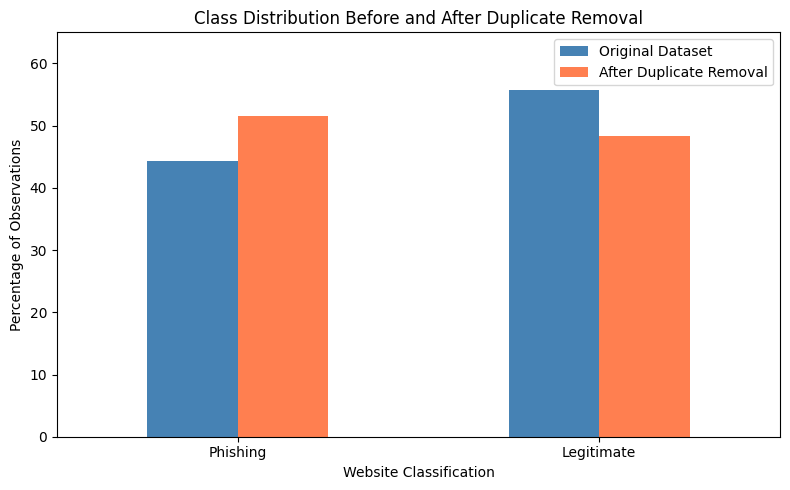

In [ ]:
# Compare class distributions before and after duplicate removal

original_counts = phishing_clean["Result"].value_counts(normalize=True)
unique_counts = phishing_unique["Result"].value_counts(normalize=True)

class_comparison = pd.DataFrame({
    "Original Dataset": original_counts,
    "After Duplicate Removal": unique_counts
}).reindex([-1, 1]) * 100

class_comparison.index = ["Phishing", "Legitimate"]

# Create the visualization
ax = class_comparison.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0,
    color=["steelblue", "coral"]
)

plt.title("Class Distribution Before and After Duplicate Removal")
plt.xlabel("Website Classification")
plt.ylabel("Percentage of Observations")
plt.ylim(0, 65)
plt.tight_layout()
plt.show()

The class distribution changed after removing exact duplicate records. In the original dataset, legitimate websites accounted for 55.69% of observations, while phishing websites accounted for 44.31%. After duplicate removal, phishing websites represented 51.62% and legitimate websites represented 48.38%. This shows that duplicate records influenced the original class balance. The prepared dataset is relatively balanced, allowing us to compare classification models without a large imbalance between the two classes.

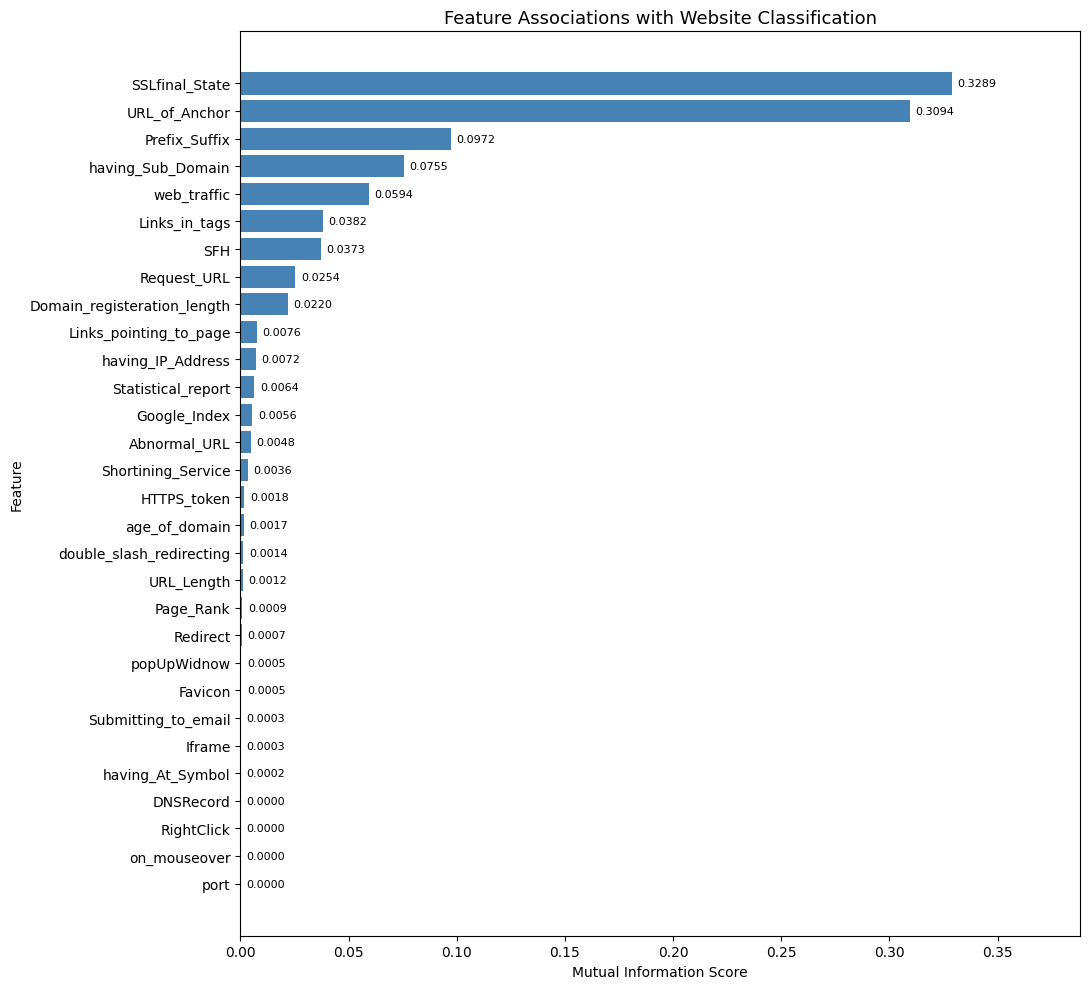

In [ ]:
# Mutual information between features and website classification
# Use training data only

from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train,
    y_train,
    discrete_features=True,
    random_state=42
)

feature_associations = pd.DataFrame({
    "Feature": X_train.columns,
    "Mutual Information": mi_scores
}).sort_values(
    by="Mutual Information",
    ascending=False
)

# Display all 30 features in one visualization
plot_data = feature_associations.sort_values(
    "Mutual Information",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 10))

bars = ax.barh(
    plot_data["Feature"],
    plot_data["Mutual Information"],
    color="steelblue"
)

# Add exact scores to the bars
ax.bar_label(
    bars,
    fmt="%.4f",
    padding=4,
    fontsize=8
)

ax.set_title(
    "Feature Associations with Website Classification",
    fontsize=13
)
ax.set_xlabel("Mutual Information Score")
ax.set_ylabel("Feature")
ax.set_xlim(0, plot_data["Mutual Information"].max() * 1.18)

plt.tight_layout()
plt.show()

The mutual information analysis shows that SSLfinal_State (0.3289) and URL_of_Anchor (0.3094) have the strongest individual associations with website classification. Their scores are considerably higher than the remaining features, including Prefix_Suffix (0.0972) and having_Sub_Domain (0.0754). Several predictors have very low mutual information scores, suggesting that they provide limited information about classification when examined individually. These findings raise the possibility that a small number of features may contribute disproportionately to model performance. We will investigate this further by comparing models trained with all features against models trained without the strongest predictors.

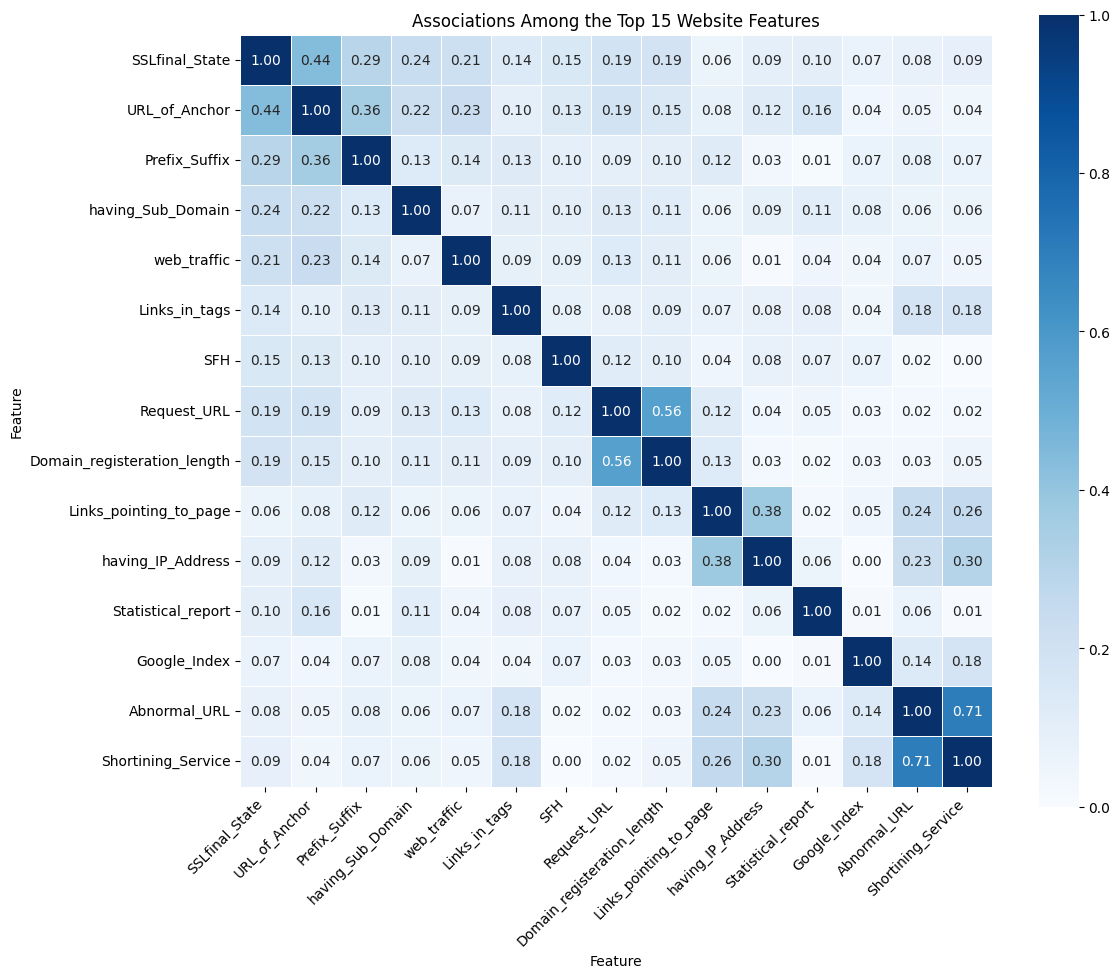

In [ ]:
# Examine associations among the 15 most informative features
# Use training data only

from scipy.stats import chi2_contingency

# Cramer's V measures association between categorical variables
def cramers_v(x, y):
    contingency = pd.crosstab(x, y)

    if min(contingency.shape) < 2:
        return 0.0

    chi2 = chi2_contingency(
        contingency,
        correction=False
    )[0]

    n = contingency.to_numpy().sum()
    r, k = contingency.shape

    return np.sqrt(
        (chi2 / n) / min(k - 1, r - 1)
    )

# Select the 15 features with highest mutual information
selected_features = feature_associations["Feature"].head(15).tolist()

# Calculate pairwise associations
association_matrix = pd.DataFrame(
    np.eye(len(selected_features)),
    index=selected_features,
    columns=selected_features
)

for feature_1 in selected_features:
    for feature_2 in selected_features:
        association_matrix.loc[feature_1, feature_2] = cramers_v(
            X_train[feature_1],
            X_train[feature_2]
        )

# Create heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    association_matrix,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.4
)

plt.title("Associations Among the Top 15 Website Features")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

The feature association heatmap shows that most predictors have relatively weak to moderate relationships with one another. The strongest association is between Abnormal_URL and Shortining_Service (0.71), followed by Request_URL and Domain_registeration_length (0.56). SSLfinal_State and URL_of_Anchor, which had the highest mutual information scores in the previous analysis, have a moderate association of 0.44. This suggests that the two features may contain some overlapping information while still capturing different website characteristics. These findings will help us interpret feature importance and investigate whether removing selected features affects model performance.

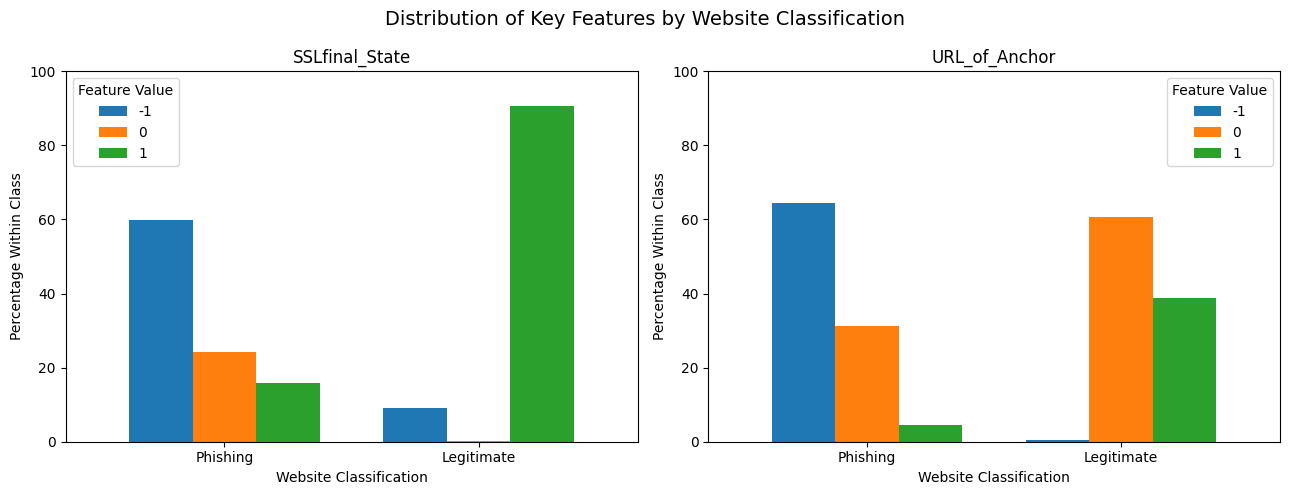

In [ ]:
# Compare feature values across phishing and legitimate websites
# Use training data only

features_to_compare = ["SSLfinal_State", "URL_of_Anchor"]

eda_data = X_train[features_to_compare].copy()
eda_data["Classification"] = y_train.map({
    -1: "Phishing",
    1: "Legitimate"
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, feature in zip(axes, features_to_compare):

    # Calculate feature-value percentages within each class
    distribution = pd.crosstab(
        eda_data["Classification"],
        eda_data[feature],
        normalize="index"
    ) * 100

    distribution = distribution.reindex(
        ["Phishing", "Legitimate"]
    )

    distribution.plot(
        kind="bar",
        ax=ax,
        rot=0,
        width=0.75
    )

    ax.set_title(feature)
    ax.set_xlabel("Website Classification")
    ax.set_ylabel("Percentage Within Class")
    ax.set_ylim(0, 100)
    ax.legend(title="Feature Value")

fig.suptitle(
    "Distribution of Key Features by Website Classification",
    fontsize=14
)

plt.tight_layout()
plt.show()

The distributions of SSLfinal_State and URL_of_Anchor show noticeable differences between phishing and legitimate websites. For SSLfinal_State, phishing websites are more frequently associated with a value of -1, while legitimate websites are predominantly associated with a value of 1. Similarly, URL_of_Anchor has a value of -1 for a much larger proportion of phishing websites than legitimate websites. These differences help explain why both features had the highest mutual information scores in the earlier analysis. The results suggest that these features may be useful for distinguishing phishing websites, although their actual influence on model performance will need to be tested during modeling and feature ablation.

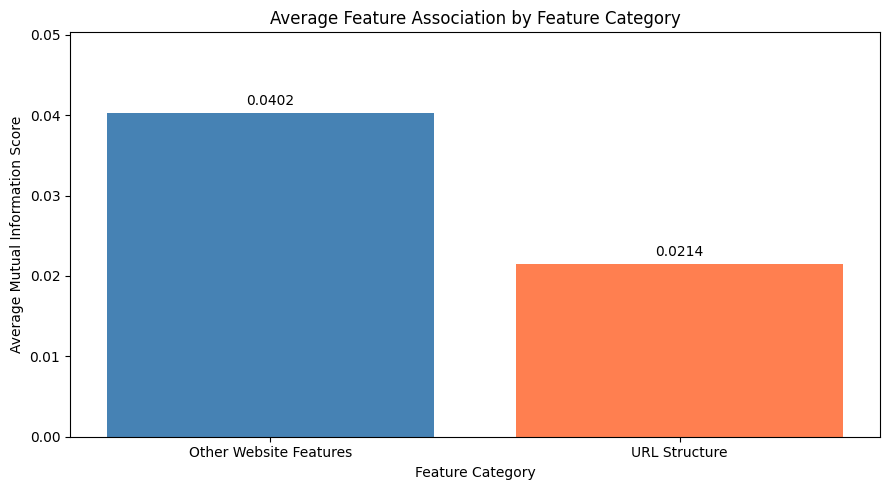

,Category,mean,max,count
0,Other Website Features,0.0402,0.3289,21
1,URL Structure,0.0214,0.0972,9


In [ ]:
# Compare URL-related features with other website features
# Use mutual information scores calculated from training data

# Define features primarily derived from URL structure
url_features = [
    "having_IP_Address",
    "URL_Length",
    "Shortining_Service",
    "having_At_Symbol",
    "double_slash_redirecting",
    "Prefix_Suffix",
    "having_Sub_Domain",
    "HTTPS_token",
    "Abnormal_URL"
]

# Assign each predictor to a preliminary category
feature_category_comparison = feature_associations.copy()

feature_category_comparison["Category"] = (
    feature_category_comparison["Feature"].apply(
        lambda feature: (
            "URL Structure"
            if feature in url_features
            else "Other Website Features"
        )
    )
)

# Calculate average mutual information by category
category_summary = (
    feature_category_comparison
    .groupby("Category")["Mutual Information"]
    .agg(["mean", "max", "count"])
    .reset_index()
)

# Create one comparison chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    category_summary["Category"],
    category_summary["mean"],
    color=["steelblue", "coral"]
)

ax.bar_label(bars, fmt="%.4f", padding=4)

ax.set_title(
    "Average Feature Association by Feature Category"
)
ax.set_xlabel("Feature Category")
ax.set_ylabel("Average Mutual Information Score")
ax.set_ylim(0, category_summary["mean"].max() * 1.25)

plt.tight_layout()
plt.show()

# Display category summary
display(category_summary.round(4))

The feature category comparison shows that Other Website Features have a higher average mutual information score (0.0402) than URL Structure features (0.0214). However, the Other Website Features category includes SSLfinal_State and URL_of_Anchor, which had the highest individual mutual information scores and may contribute substantially to the difference. These findings do not establish which feature group produces better classification performance, so we will compare the groups through separate modeling experiments.

For this analysis, URL Structure refers to the nine predictors derived primarily from the URL string, while Other Website Features includes the remaining 21 predictors. Some features in the second category, such as URL_of_Anchor, still involve URL-related information but require examining webpage content. Therefore, these categories distinguish URL-string features from other website characteristics rather than all URL-related features from non-URL features.

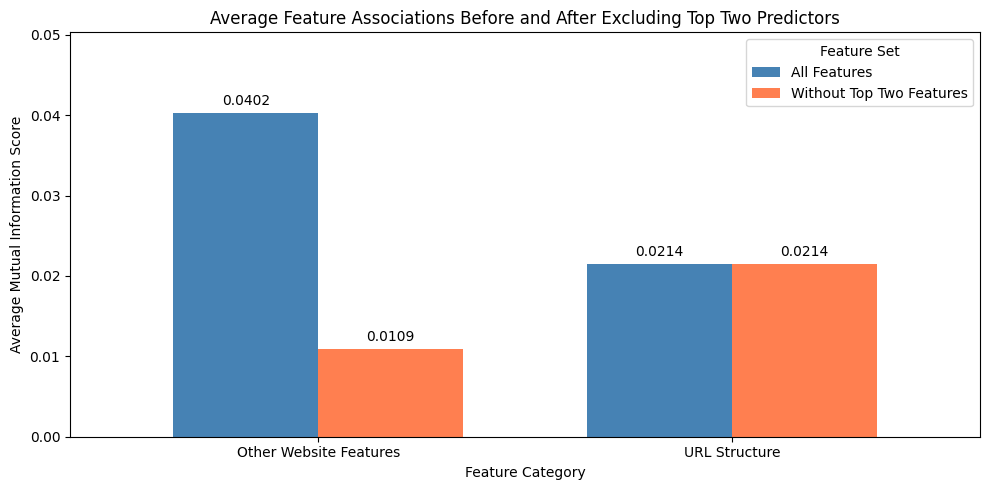

,All Features,Without Top Two Features
Category,,
Other Website Features,0.0402,0.0109
URL Structure,0.0214,0.0214


In [ ]:
# Compare feature category associations before and after excluding the two strongest predictors
# Uses mutual information scores calculated from training data

top_two_features = ["SSLfinal_State", "URL_of_Anchor"]

# Original average mutual information by category
original_category_means = (
    feature_category_comparison
    .groupby("Category")["Mutual Information"]
    .mean()
)

# Exclude the two strongest features
reduced_feature_data = feature_category_comparison[
    ~feature_category_comparison["Feature"].isin(top_two_features)
].copy()

# Recalculate category averages
reduced_category_means = (
    reduced_feature_data
    .groupby("Category")["Mutual Information"]
    .mean()
)

# Combine results
category_ablation_comparison = pd.DataFrame({
    "All Features": original_category_means,
    "Without Top Two Features": reduced_category_means
})

# Create grouped bar chart
ax = category_ablation_comparison.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    color=["steelblue", "coral"],
    width=0.7
)

# Label bars with exact values
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=4
    )

plt.title("Average Feature Associations Before and After Excluding Top Two Predictors")
plt.xlabel("Feature Category")
plt.ylabel("Average Mutual Information Score")
plt.ylim(0, category_ablation_comparison.max().max() * 1.25)
plt.legend(title="Feature Set")
plt.tight_layout()
plt.show()

# Display exact comparison values
display(category_ablation_comparison.round(4))

After excluding SSLfinal_State and URL_of_Anchor, the average mutual information score for Other Website Features decreased from 0.0402 to 0.0109, a reduction of approximately 73%. The URL Structure category remained unchanged at 0.0214 because neither excluded feature belongs to that group. This indicates that the higher average association observed for Other Website Features was largely influenced by the two strongest predictors. The results support our professor's concern that a small number of features may account for much of the information associated with website classification. However, this analysis does not establish how much model performance depends on these features. We will investigate that through controlled feature-ablation experiments during modeling.

### EDA Findings and Modeling Implications

The exploratory analysis identified several patterns relevant to phishing website detection. Removing exact duplicate records changed the class distribution, resulting in a relatively balanced modeling dataset. Mutual information analysis identified SSLfinal_State and URL_of_Anchor as the two features most strongly associated with website classification, while several other predictors showed considerably weaker individual associations.

The feature association heatmap revealed some relationships between predictors, including a moderate association between SSLfinal_State and URL_of_Anchor. Class-specific distributions further demonstrated that the values of these two features differ substantially between phishing and legitimate websites.

When comparing feature categories, Other Website Features initially had a higher average mutual information score than URL Structure features. However, removing the two strongest predictors substantially reduced that average, indicating that the original difference was largely driven by those features.

These findings will guide the modeling experiments. We will establish baseline performance, compare classification algorithms, and investigate how model performance changes when influential features are removed. We will also compare URL-structure-only models against models using other website features to assess their relative predictive usefulness.

Although these exploratory results identify promising predictors, they do not establish model accuracy, generalization, or real-world deployment suitability. Those questions will be addressed through validation, testing, and feature sensitivity experiments.

## Modeling

We begin with a majority-class baseline to establish a reference point for evaluating phishing detection models. The baseline predicts the most common class in the training dataset without learning relationships between website features. We evaluate it using the validation dataset, reserving the test dataset for final evaluation.

In [ ]:
# Majority-class baseline
# Evaluate on validation data only

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_val)

# Phishing (-1) is the positive class
tn, fp, fn, tp = confusion_matrix(
    y_val,
    baseline_predictions,
    labels=[1, -1]
).ravel()

baseline_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Phishing Precision",
        "Phishing Recall",
        "Phishing F1",
        "False Positive Rate"
    ],
    "Validation Score": [
        accuracy_score(y_val, baseline_predictions),
        precision_score(y_val, baseline_predictions, pos_label=-1, zero_division=0),
        recall_score(y_val, baseline_predictions, pos_label=-1, zero_division=0),
        f1_score(y_val, baseline_predictions, pos_label=-1, zero_division=0),
        fp / (fp + tn)
    ]
})

print("Baseline prediction:", baseline_model.classes_[
    np.argmax(baseline_model.class_prior_)
])
print("Validation observations:", len(y_val))
print("\nConfusion matrix (rows: actual, columns: predicted)")
print("Label order: Legitimate (1), Phishing (-1)")
print(confusion_matrix(y_val, baseline_predictions, labels=[1, -1]))

display(baseline_results.round(4))

Baseline prediction: -1
Validation observations: 1172

Confusion matrix (rows: actual, columns: predicted)
Label order: Legitimate (1), Phishing (-1)
[[  0 560]
 [  0 612]]


,Metric,Validation Score
0,Accuracy,0.5222
1,Phishing Precision,0.5222
2,Phishing Recall,1.0000
3,Phishing F1,0.6861
4,False Positive Rate,1.0000


### Baseline Model or Analytical Benchmark

A majority-class baseline was developed using scikit-learn's DummyClassifier with the `most_frequent` strategy. The model was trained on 3,508 observations and evaluated on the separate validation dataset containing 1,172 observations. The test dataset was not used.

The baseline predicted every website as phishing because phishing was the majority class in the training data. Although it achieved 100% phishing recall, it incorrectly classified all legitimate websites as phishing, resulting in a 100% false positive rate.

| Metric | Baseline result | Interpretation |
|---|---|---|
| Accuracy | 52.22% | Correctly classified 612 of 1,172 validation observations. |
| Phishing Precision | 52.22% | Only 52.22% of predicted phishing websites were actually phishing. |
| Phishing Recall | 100.00% | Identified all 612 phishing websites. |
| Phishing F1 | 68.61% | Reflects the imbalance between perfect recall and limited precision. |
| False Positive Rate | 100.00% | Incorrectly flagged all 560 legitimate websites. |

These results establish a preliminary benchmark rather than a usable phishing detection system. Future Logistic Regression, Decision Tree, and Random Forest models will be evaluated against this baseline, with particular attention to phishing recall, false positives, F1 score, and precision-recall performance.